In [5]:
!pip install segmentation-models-pytorch
!pip install albumentations opencv-python

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import segmentation_models_pytorch as smp
import torch.nn as nn
import albumentations as A
import cv2

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
def encoded_pixels_to_masks(fname: str, df: pd.DataFrame):
    fname_df = df[df['ImageId'] == fname]
    masks = np.zeros((256 * 1600, 4), dtype=int)

    for i_row, row in fname_df.iterrows():
        cls_id = row['ClassId']
        encoded_pixels = row['EncodedPixels']
        if encoded_pixels is not np.nan:
            pixel_list = list(map(int, encoded_pixels.split(' ')))
            for i in range(0, len(pixel_list), 2):
                start_pixel = pixel_list[i] - 1
                num_pixel = pixel_list[i+1]
                masks[start_pixel:(start_pixel+num_pixel), cls_id-1] = 1

    masks = masks.reshape(256, 1600, 4, order='F')

    return masks

def masks_to_encoded_pixels(masks: np.ndarray):
    masks = masks.reshape(256*1600, 4, order='F')
    encoded_pixels_list = []
    for cls_id in range(4):
        cls_mask = masks[:, cls_id]
        cls_mask = cls_mask.reshape(256, 1600, order='F')
        cls_mask = cls_mask.T.flatten()
        prev_pixel = 0
        prev_pixel_val = 0
        encoded_pixels = []
        for i, pixel_val in enumerate(cls_mask):
            if pixel_val != prev_pixel_val:
                if pixel_val == 1:
                    start_pixel = i + 1
                    encoded_pixels.append(start_pixel - prev_pixel)
                else:
                    num_pixel = i - prev_pixel
                    encoded_pixels.append(num_pixel)
                prev_pixel = i
                prev_pixel_val = pixel_val
        encoded_pixels_list.append(encoded_pixels)
    return encoded_pixels_list

### Sample example

In [8]:
train_val_csv = 'drive/MyDrive/data/train.csv'
test_csv = 'drive/MyDrive/data/test.csv'

df = pd.read_csv(train_val_csv)

df.ImageId

,ImageId
0,0002cc93b.jpg
1,0007a71bf.jpg
2,000a4bcdd.jpg
3,000f6bf48.jpg
4,0014fce06.jpg
...,...
7090,ffcf72ecf.jpg
7091,fff02e9c5.jpg
7092,fffe98443.jpg
7093,ffff4eaa8.jpg


In [9]:
# let's look at encoded pixels for the first image
img_id = '0002cc93b.jpg'
df[df.ImageId==img_id]

,ImageId,ClassId,EncodedPixels
0,0002cc93b.jpg,1,29102 12 29346 24 29602 24 29858 24 30114 24 3...


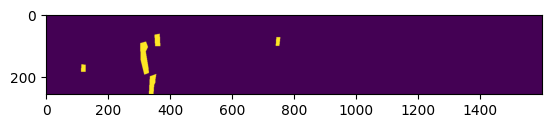

In [10]:
masks = encoded_pixels_to_masks(img_id, df, )
plt.imshow(masks[:,:,0]*255)

In [11]:
img = Image.open(os.path.join('drive/MyDrive/data/train_images',img_id))

In [12]:
np.array(img).shape

(256, 1600, 3)

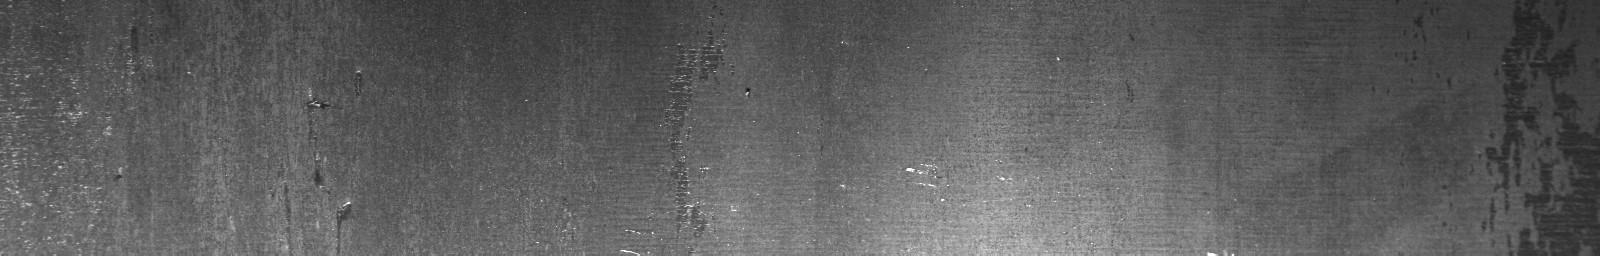

In [13]:
img

In [14]:
# let's encode masks back to encoded pixels
np.array(masks_to_encoded_pixels(masks)[0])

array([29102,    12,   233,    24,   233,    24,   233,    24,   233,
          24,   233,    24,   233,    24,   233,    24,   234,    23,
         234,    23,   234,    23,   234,    23,   234,    23,   234,
          23,   234,    23, 45221,    27,   230,    55,   201,    60,
         197,    64,   193,    68,   189,    72,   184,    77,   180,
          81,   176,    85,   172,    89,   167,    94,   163,    98,
         159,   102,   154,   105,   152,   105,   152,   104,   153,
         104,   152,   105,   152,    31,     5,    69,   155,    27,
          13,    63,   158,    22,    21,    57,   161,    17,    29,
          50,   164,    13,    37,    44,   167,     8,    45,    37,
         171,     3,    53,    31,   232,    25,   238,    18,   249,
           8,   314,    10,   228,    29,   210,    47,   200,    57,
         200,    57,   199,    58,   199,    58,   199,    58,   198,
          59,   198,    59,   198,    59,   197,    60,   197,    60,
         197,    60,

### Your code starts from here

In [15]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [16]:
class SeverstalSteelDataset(Dataset):
    def __init__(self, fnames, df, img_dir, transform=None):
        self.df = df
        self.img_dir = img_dir
        self.fnames = [f for f in fnames if os.path.exists(os.path.join(img_dir, f))]
        self.transform = transform
        self.resized_size = (256, 256)

    def __len__(self):
        return len(self.fnames)

    def __getitem__(self, idx):
      img_id = self.fnames[idx]
      img_path = os.path.join(self.img_dir, img_id)
      img = Image.open(img_path).convert('RGB')
      img = np.array(img)

      img = cv2.resize(img, self.resized_size, interpolation=cv2.INTER_AREA)

      masks = encoded_pixels_to_masks(img_id, self.df)

      masks_resized = []
      for i in range(4):
          mask_channel = cv2.resize(
              masks[:, :, i],
              self.resized_size,
              interpolation=cv2.INTER_NEAREST
          )
          masks_resized.append(mask_channel)
      masks = np.stack(masks_resized, axis=2)

      img = torch.tensor(img, dtype=torch.float32).permute(2, 0, 1) / 255.0
      masks = torch.tensor(masks, dtype=torch.float32).permute(2, 0, 1)

      mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
      std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
      img = (img - mean) / std

      return img_id, img, masks

def collate_fn(batch_items):
    batched_fnames = [item[0] for item in batch_items]
    batched_imgs = torch.stack([item[1] for item in batch_items])
    batched_masks = torch.stack([item[2] for item in batch_items])
    return batched_fnames, batched_imgs, batched_masks

In [17]:
!pip install segmentation-models-pytorch

class SegModel(torch.nn.Module):
    def __init__(self):
        super(SegModel, self).__init__()
        self.model = smp.Unet(
            encoder_name="resnet34",
            encoder_weights="imagenet",
            in_channels=3,
            classes=4,
            activation=None,
            decoder_use_batchnorm=True,
            decoder_dropout=0.2
        )

    def forward(self, x):
        return self.model(x)

def dice_score_per_class(pred, target, smooth=1e-6, threshold=0.5):
    pred_binary = (torch.sigmoid(pred) > threshold).float()
    intersection = (pred_binary * target).sum(dim=(2, 3))
    union = pred_binary.sum(dim=(2, 3)) + target.sum(dim=(2, 3))
    dice = (2. * intersection + smooth) / (union + smooth)
    dice_per_class = dice.mean(dim=0)
    mean_dice = dice_per_class.mean()

    return dice_per_class.detach().cpu().numpy(), mean_dice.item()

def dice_score(pred, target, smooth=1e-6, threshold=0.5):
    pred_binary = (torch.sigmoid(pred) > threshold).float()
    intersection = (pred_binary * target).sum()
    return (2 * intersection + smooth) / (pred_binary.sum() + target.sum() + smooth)

In [18]:
def load_data(train_val_csv, train_val_img_dir, batch_size=8, subset_ratio=1.0):
    train_val_df = pd.read_csv(train_val_csv)
    train_val_fnames = pd.unique(train_val_df.ImageId)

    num_samples = int(len(train_val_fnames) * subset_ratio)
    train_val_fnames = train_val_fnames[:num_samples]

    train_fnames, val_fnames = train_test_split(
        train_val_fnames, test_size=0.2, random_state=42
    )

    train_transform = A.Compose([
        A.HorizontalFlip(p=0.5),
    ])

    train_dataset = SeverstalSteelDataset(
        train_fnames, train_val_df, train_val_img_dir,
        transform=train_transform
    )
    val_dataset = SeverstalSteelDataset(
        val_fnames, train_val_df, train_val_img_dir
    )

    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn
    )
    val_loader = DataLoader(
        val_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn
    )

    return train_loader, val_loader

In [77]:
def init_model():
    model = SegModel()
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)

    model = model.to(device)
    return model, criterion, optimizer

def train(model, criterion, optimizer, train_loader, val_loader, epochs=10):
    model.train()
    best_val_dice = 0.0
    best_model_state = None

    for epoch in range(epochs):
        train_loss = 0.0
        train_dice = 0.0
        train_dice_per_class = np.array([0.0, 0.0, 0.0, 0.0])

        for batch_idx, (fnames, imgs, masks) in enumerate(train_loader):
            imgs = imgs.to(device)
            masks = masks.to(device)

            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, masks)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

            dice_scores, avg_dice = dice_score_per_class(outputs, masks)
            train_dice += avg_dice
            train_dice_per_class += dice_scores

            if batch_idx % 100 == 0:
                print(f'Epoch {epoch}, Batch {batch_idx}, Loss: {loss.item():.4f}')

        model.eval()
        val_loss = 0.0
        val_dice = 0.0
        val_dice_per_class = np.array([0.0, 0.0, 0.0, 0.0])

        with torch.no_grad():
            for fnames, imgs, masks in val_loader:
                imgs = imgs.to(device)
                masks = masks.to(device)

                outputs = model(imgs)
                loss = criterion(outputs, masks)
                val_loss += loss.item()

                dice_scores, avg_dice = dice_score_per_class(outputs, masks)
                val_dice += avg_dice
                val_dice_per_class += dice_scores

        train_loss /= len(train_loader)
        train_dice /= len(train_loader)
        train_dice_per_class /= len(train_loader)

        val_loss /= len(val_loader)
        val_dice /= len(val_loader)
        val_dice_per_class /= len(val_loader)

        print(f'Epoch {epoch}: Train Loss: {train_loss:.4f}, 'f'Val Loss: {val_loss:.4f}, Val Dice: {val_dice:.4f}')

        if val_dice > best_val_dice:
            best_val_dice = val_dice
            best_model_state = model.state_dict().copy()
            torch.save(model.state_dict(), 'best_model.pth')

        model.train()

    if best_model_state:
        model.load_state_dict(best_model_state)
        print(f"Loaded best model with Val Dice: {best_val_dice:.4f}")

    return model

def evaluate(model, loader, orig_size=(256, 1600), threshold=0.5):
    model.eval()
    submission_data = []

    with torch.no_grad():
        for fnames, imgs, masks in loader:
            imgs = imgs.to(device)
            outputs = model(imgs)
            pred_masks = (torch.sigmoid(outputs) > threshold).cpu().numpy()

            for i, fname in enumerate(fnames):
                pred_mask_orig_size = np.zeros((orig_size[0], orig_size[1], 4), dtype=np.uint8)

                for cls_id in range(4):
                    mask_cls = pred_masks[i, cls_id]

                    mask_resized = cv2.resize(
                        mask_cls.astype(np.uint8),
                        (orig_size[1], orig_size[0]),
                        interpolation=cv2.INTER_NEAREST
                    )
                    pred_mask_orig_size[:, :, cls_id] = mask_resized

                encoded_pixels_list = []

                for cls_id in range(4):
                    mask = pred_mask_orig_size[:, :, cls_id]
                    mask_t = mask.T
                    mask_flat = mask_t.flatten()

                    encoded_pixels = []
                    start = None
                    length = 0

                    for idx, pixel in enumerate(mask_flat):
                        if pixel == 1:
                            if start is None:
                                start = idx
                            length += 1
                        elif start is not None:
                            encoded_pixels.extend([start + 1, length])
                            start = None
                            length = 0

                    if start is not None:
                        encoded_pixels.extend([start + 1, length])

                    encoded_pixels_list.append(encoded_pixels)

                for cls_id in range(4):
                    encoded_pixels = encoded_pixels_list[cls_id]
                    if len(encoded_pixels) > 0:
                        rle_string = ' '.join(map(str, encoded_pixels))
                        submission_data.append({
                            'ImageId': fname,
                            'ClassId': cls_id + 1,
                            'EncodedPixels': rle_string
                        })
                    else:
                        submission_data.append({
                            'ImageId': fname,
                            'ClassId': cls_id + 1,
                            'EncodedPixels': ''
                        })

    submission_df = pd.DataFrame(submission_data)
    return submission_df

In [ ]:
train_loader, val_loader = load_data(
    'drive/MyDrive/data/train.csv',
    'drive/MyDrive/data/train_images',
    batch_size=8,
    subset_ratio=1
)

model, criterion, optimizer = init_model()

print("Starting training...")
model = train(model, criterion, optimizer, train_loader, val_loader, epochs=8)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

Starting training...
Epoch 0, Batch 0, Loss: 0.7819
Epoch 0, Batch 100, Loss: 0.4238
Epoch 0, Batch 200, Loss: 0.2946
Epoch 0, Batch 300, Loss: 0.1921
Epoch 0, Batch 400, Loss: 0.1238
Epoch 0, Batch 500, Loss: 0.1028
Epoch 0, Batch 600, Loss: 0.0797
Epoch 0: Train Loss: 0.2360, Val Loss: 0.0752, Val Dice: 0.7746
Epoch 1, Batch 0, Loss: 0.0653
Epoch 1, Batch 100, Loss: 0.1058
Epoch 1, Batch 200, Loss: 0.0639
Epoch 1, Batch 300, Loss: 0.0377
Epoch 1, Batch 400, Loss: 0.0393
Epoch 1, Batch 500, Loss: 0.0415
Epoch 1, Batch 600, Loss: 0.0479
Epoch 1: Train Loss: 0.0553, Val Loss: 0.0441, Val Dice: 0.7871
Epoch 2, Batch 0, Loss: 0.0400
Epoch 2, Batch 100, Loss: 0.0413
Epoch 2, Batch 200, Loss: 0.0294
Epoch 2, Batch 300, Loss: 0.0423
Epoch 2, Batch 400, Loss: 0.0308
Epoch 2, Batch 500, Loss: 0.0229
Epoch 2, Batch 600, Loss: 0.0312
Epoch 2: Train Loss: 0.0386, Val Loss: 0.0351, Val Dice: 0.7937
Epoch 3, Batch 0, Loss: 0.0259
Epoch 3, Batch 100, Loss: 0.0193
Epoch 3, Batch 200, Loss: 0.0174
Epo

In [55]:
submission_df = evaluate(model, val_loader)

In [76]:
submission_df = submission_df[submission_df['EncodedPixels'] != '']

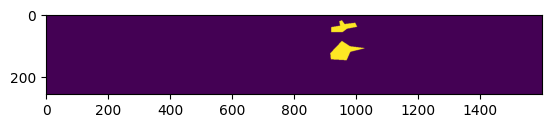

In [61]:
img_id = 'ec52fac2d.jpg'
cls = df[df.ImageId==img_id]['ClassId'] - 1
masks = encoded_pixels_to_masks(img_id, df, )
plt.imshow(masks[:,:,cls]*255)

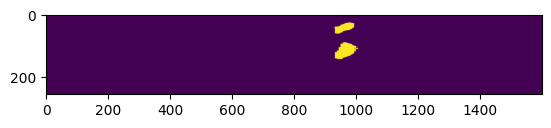

In [62]:
cls = submission_df[submission_df.ImageId==img_id]['ClassId'] - 1
masks = encoded_pixels_to_masks(img_id, submission_df, )
plt.imshow(masks[:,:,cls]*255)

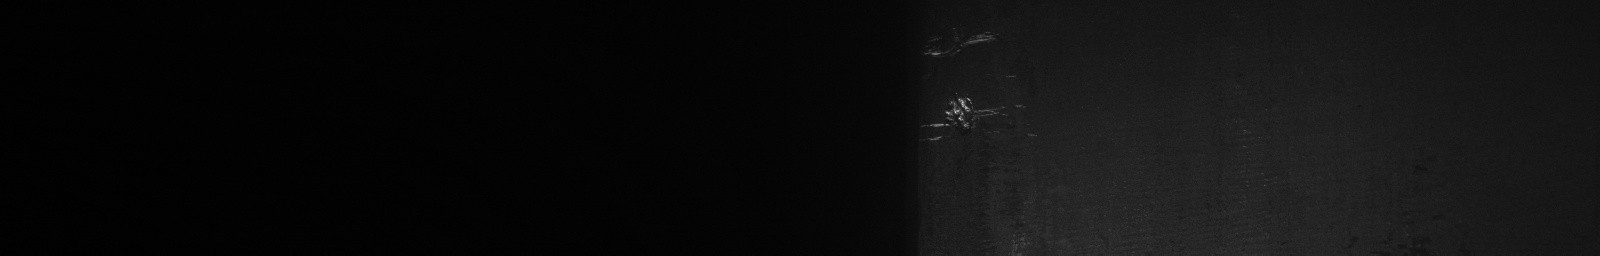

In [64]:
img = Image.open(os.path.join('drive/MyDrive/data/train_images',img_id))
img

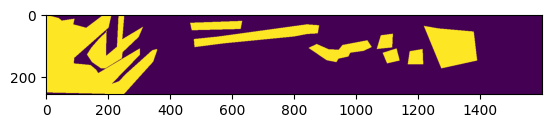

In [73]:
img_id = 'c5b9dccf7.jpg'
cls = df[df.ImageId==img_id]['ClassId'] - 1
masks = encoded_pixels_to_masks(img_id, df, )
plt.imshow(masks[:,:,cls]*255)

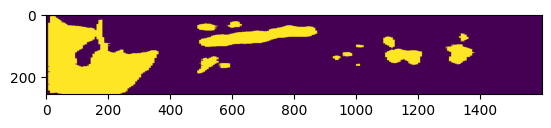

In [74]:
cls = submission_df[submission_df.ImageId==img_id]['ClassId'] - 1
masks = encoded_pixels_to_masks(img_id, submission_df, )
plt.imshow(masks[:,:,cls]*255)

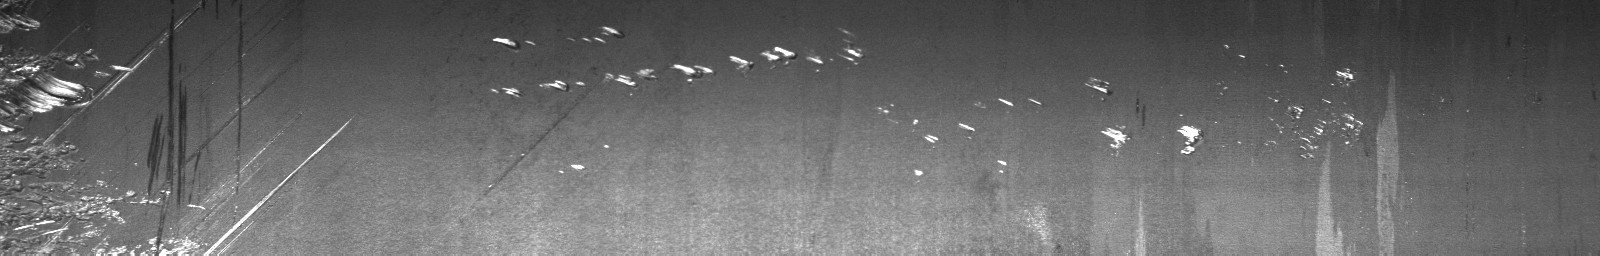

In [75]:
img = Image.open(os.path.join('drive/MyDrive/data/train_images',img_id))
img